# Agricultural Crop Production Analysis
Introduction to Data Analytics | Group BT_DA_05 | Project ID DA-023

Dataset: Agriculture Crops Production in India (Kaggle). Values are index numbers of Production, Area and Yield for 55 crops from 2006-07 to 2010-11.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
df = pd.read_csv("agriculture_crops_raw.csv")
df.shape

(55, 16)

In [3]:
df.head()

               Crop  Production 2006-07  ...  Yield 2009-10  Yield 2010-11
0  Total Foodgrains               158.8  ...          126.5          135.9
1              Rice               200.8  ...          118.9          125.2
2             Wheat               131.6  ...          120.0          126.3
3             Jowar               124.3  ...          105.0          115.8
4             Bajra               136.4  ...          119.0          175.8

[5 rows x 16 columns]

In [4]:
df.columns

Index(['Crop', 'Production 2006-07', 'Production 2007-08',
       'Production 2008-09', 'Production 2009-10', 'Production 2010-11',
       'Area 2006-07', 'Area 2007-08', 'Area 2008-09', 'Area 2009-10',
       'Area 2010-11', 'Yield 2006-07', 'Yield 2007-08', 'Yield 2008-09',
       'Yield 2009-10', 'Yield 2010-11'],
      dtype='str')

In [5]:
df.dtypes

Crop                      str
Production 2006-07    float64
Production 2007-08    float64
Production 2008-09    float64
Production 2009-10    float64
Production 2010-11    float64
Area 2006-07          float64
Area 2007-08          float64
Area 2008-09          float64
Area 2009-10          float64
Area 2010-11          float64
Yield 2006-07         float64
Yield 2007-08         float64
Yield 2008-09         float64
Yield 2009-10         float64
Yield 2010-11         float64
dtype: object

## 2. Data cleaning

In [6]:
df.isnull().sum()

Crop                  0
Production 2006-07    0
Production 2007-08    0
Production 2008-09    0
Production 2009-10    0
Production 2010-11    0
Area 2006-07          0
Area 2007-08          0
Area 2008-09          0
Area 2009-10          0
Area 2010-11          0
Yield 2006-07         0
Yield 2007-08         0
Yield 2008-09         0
Yield 2009-10         0
Yield 2010-11         0
dtype: int64

In [7]:
print("Rows before:", len(df))
df = df.drop_duplicates()
print("Rows after:", len(df))

Rows before: 55
Rows after: 55


In [8]:
print("Duplicate crop names:", df['Crop'].duplicated().sum())

Duplicate crop names: 0


In [9]:
# Clean the crop names (extra spaces, missing space after '&')
df['Crop'] = df['Crop'].str.strip().str.replace('&', ' & ', regex=False).str.replace(r'\s+', ' ', regex=True)
df['Crop'].tolist()

['Total Foodgrains', 'Rice', 'Wheat', 'Jowar', 'Bajra', 'Maize', 'Ragi', 'Small millets', 'Barley', 'Coarse Cereals', 'Cereals', 'Gram', 'Arhar', 'Other Pulses', 'Total Pulses', 'Total Non-Food grains', 'Total Oilseeds', 'Groundnut', 'Sesamum', 'Rapeseed & Mustard', 'Linseed', 'Castor seed', 'Safflower', 'Niger seed', 'Sunflower', 'Soyabean', 'Nine Oilseeds', 'Coconut', 'Cotton seed', 'Total Fibers', 'Cotton(lint)', 'Jute', 'Mesta', 'Jute & Mesta', 'Sannhamp', 'Tea', 'Coffee', 'Rubber', 'Total Spices', 'Black pepper', 'Dry chilies', 'Dry ginger', 'Turmeric', 'Arecanut', 'Cardamom', 'Coriander', 'Garlic', 'Total Fruits & Vegetables', 'Potato', 'Tapioca', 'Sweet potato', 'Onion', 'Banana', 'Sugarcane', 'Tobacco']

In [10]:
# Validation: Yield index should be close to Production / Area x 100
for y in ['2006-07', '2007-08', '2008-09', '2009-10', '2010-11']:
    calc = df['Production ' + y] / df['Area ' + y] * 100
    print(y, "max difference:", round((calc - df['Yield ' + y]).abs().max(), 2))

2006-07 max difference: 0.4
2007-08 max difference: 11.34
2008-09 max difference: 1.34
2009-10 max difference: 26.07
2010-11 max difference: 0.18


In [11]:
# Which crops have a mismatch of more than 2 points?
for y in ['2006-07', '2007-08', '2008-09', '2009-10', '2010-11']:
    calc = df['Production ' + y] / df['Area ' + y] * 100
    diff = (calc - df['Yield ' + y]).abs()
    for crop, d in zip(df.loc[diff > 2, 'Crop'], diff[diff > 2]):
        print(y, crop, "difference:", round(d, 1))

2007-08 Tobacco difference: 11.3
2009-10 Sannhamp difference: 26.1
2009-10 Tobacco difference: 11.3


## 3. Add Category and Type columns
The file mixes single crops with total/group rows (for example Total Foodgrains, Cereals). Group rows are marked so they are not counted twice in the analysis.

In [12]:
category_map = {
    'Cereals': ['Rice', 'Wheat', 'Jowar', 'Bajra', 'Maize', 'Ragi', 'Small millets', 'Barley'],
    'Pulses': ['Gram', 'Arhar', 'Other Pulses'],
    'Oilseeds': ['Groundnut', 'Sesamum', 'Rapeseed & Mustard', 'Linseed', 'Castor seed',
                 'Safflower', 'Niger seed', 'Sunflower', 'Soyabean'],
    'Fibres': ['Cotton seed', 'Cotton(lint)', 'Jute', 'Mesta', 'Sannhamp'],
    'Plantation': ['Coconut', 'Tea', 'Coffee', 'Rubber'],
    'Spices': ['Black pepper', 'Dry chilies', 'Dry ginger', 'Turmeric', 'Arecanut',
               'Cardamom', 'Coriander', 'Garlic'],
    'Fruits & Vegetables': ['Potato', 'Tapioca', 'Sweet potato', 'Onion', 'Banana'],
    'Other Cash Crops': ['Sugarcane', 'Tobacco'],
}
crop_to_cat = {crop: cat for cat, crops in category_map.items() for crop in crops}
df['Category'] = df['Crop'].map(crop_to_cat).fillna('Group Total')
df['Type'] = np.where(df['Category'] == 'Group Total', 'Group Total', 'Individual Crop')
df['Type'].value_counts()

Type
Individual Crop    44
Group Total        11
Name: count, dtype: int64

In [13]:
df.to_csv("cleaned_agriculture_crops.csv", index=False)
df.shape

(55, 18)

In [14]:
df_crops = df[df['Type'] == 'Individual Crop'].copy()
years = ['2006-07', '2007-08', '2008-09', '2009-10', '2010-11']
df_crops.shape

(44, 18)

## 4. Analysis and charts

### Chart 1: Number of crops by category

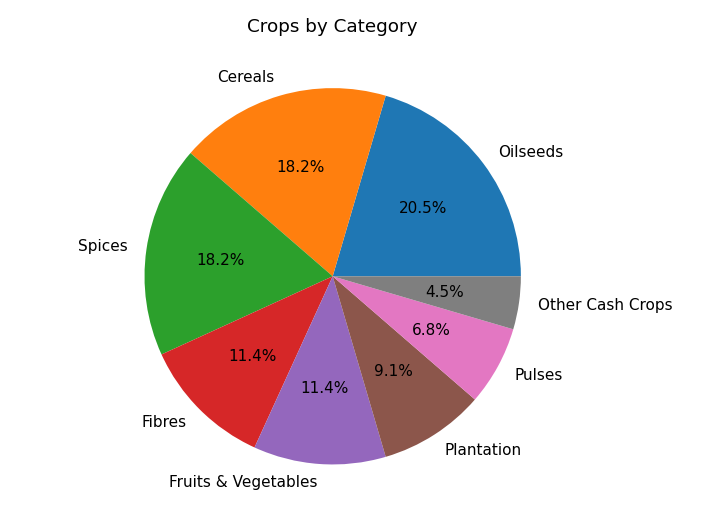

In [15]:
df_crops['Category'].value_counts().plot(kind='pie', autopct='%1.1f%%', title='Crops by Category')
plt.ylabel('')
plt.show()

### Chart 2: Top 10 crops by production (2010-11)

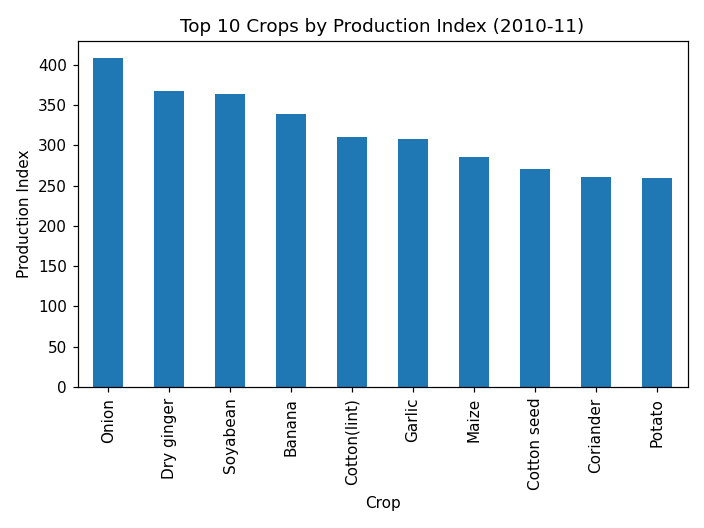

Crop
Onion           409.1
Dry ginger      368.1
Soyabean        364.4
Banana          339.4
Cotton(lint)    310.8
Garlic          308.2
Maize           286.0
Cotton seed     271.3
Coriander       261.3
Potato          259.1
Name: Production 2010-11, dtype: float64

In [16]:
top10 = df_crops.set_index('Crop')['Production 2010-11'].sort_values(ascending=False).head(10)
top10.plot(kind='bar', title='Top 10 Crops by Production Index (2010-11)')
plt.xlabel('Crop')
plt.ylabel('Production Index')
plt.show()
top10

### Chart 3: Average production, area and yield by year

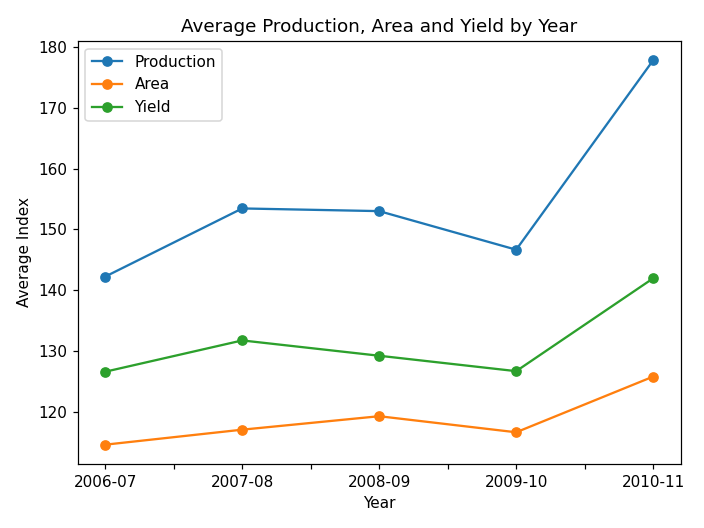

         Production   Area  Yield
2006-07       142.2  114.6  126.6
2007-08       153.5  117.1  131.7
2008-09       153.0  119.3  129.2
2009-10       146.7  116.6  126.7
2010-11       177.8  125.8  142.0

In [17]:
trend = pd.DataFrame({
    'Production': [df_crops['Production ' + y].mean() for y in years],
    'Area': [df_crops['Area ' + y].mean() for y in years],
    'Yield': [df_crops['Yield ' + y].mean() for y in years]}, index=years)
trend.plot(kind='line', marker='o', title='Average Production, Area and Yield by Year')
plt.xlabel('Year')
plt.ylabel('Average Index')
plt.show()
trend.round(1)

### Chart 4: Average production by category (2010-11)

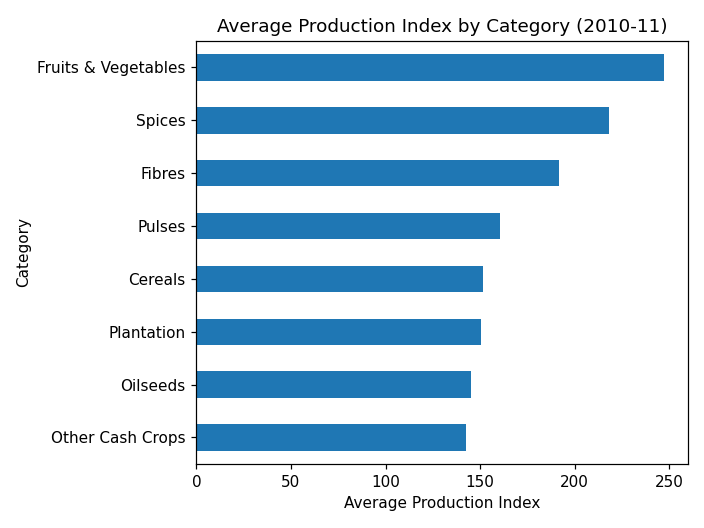

Category
Other Cash Crops       142.6
Oilseeds               145.1
Plantation             150.2
Cereals                151.3
Pulses                 160.6
Fibres                 191.6
Spices                 218.3
Fruits & Vegetables    247.2
Name: Production 2010-11, dtype: float64

In [18]:
cat_prod = df_crops.groupby('Category')['Production 2010-11'].mean().sort_values()
cat_prod.plot(kind='barh', title='Average Production Index by Category (2010-11)')
plt.xlabel('Average Production Index')
plt.ylabel('Category')
plt.show()
cat_prod.round(1)

### Chart 5: Top 10 crops by production growth (2006-07 to 2010-11)

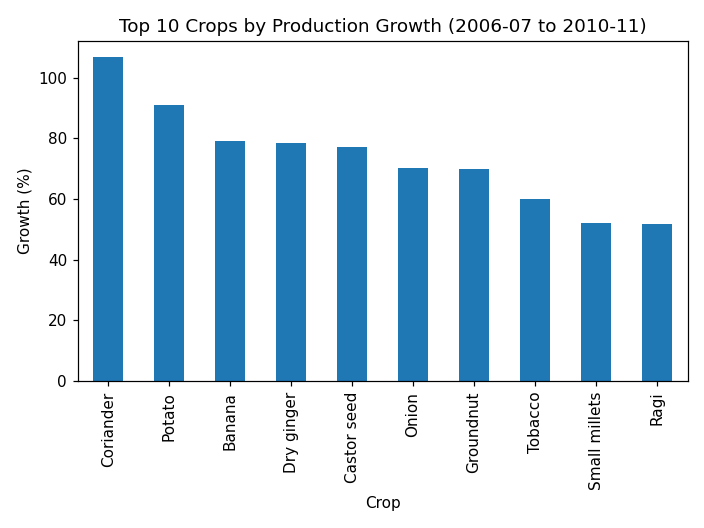

Crop
Coriander             106.7
Potato                 90.9
Banana                 79.3
Dry ginger             78.4
Castor seed            77.1
Onion                  70.1
Groundnut              69.9
Tobacco                59.9
Small millets          52.1
Ragi                   51.9
Cotton(lint)           45.8
Cotton seed            45.8
Sesamum                44.4
Soyabean               43.9
Maize                  43.9
Garlic                 36.3
Gram                   29.8
Other Pulses           29.0
Turmeric               26.2
Barley                 25.2
Arhar                  23.6
Bajra                  23.1
Coffee                 16.7
Wheat                  14.6
Sannhamp               12.3
Rapeseed & Mustard      9.9
Sweet potato            8.6
Rice                    2.8
Cardamom                1.9
Arecanut                1.0
Tea                    -0.2
Dry chilies            -1.6
Jowar                  -2.0
Rubber                 -2.5
Jute                   -3.0
Sugarcane      

In [19]:
df_crops['Growth %'] = (df_crops['Production 2010-11'] - df_crops['Production 2006-07']) / df_crops['Production 2006-07'] * 100
growth = df_crops.set_index('Crop')['Growth %'].sort_values(ascending=False)
growth.head(10).plot(kind='bar', title='Top 10 Crops by Production Growth (2006-07 to 2010-11)')
plt.xlabel('Crop')
plt.ylabel('Growth (%)')
plt.show()
growth.round(1)

### Chart 6: Area vs production (2010-11)

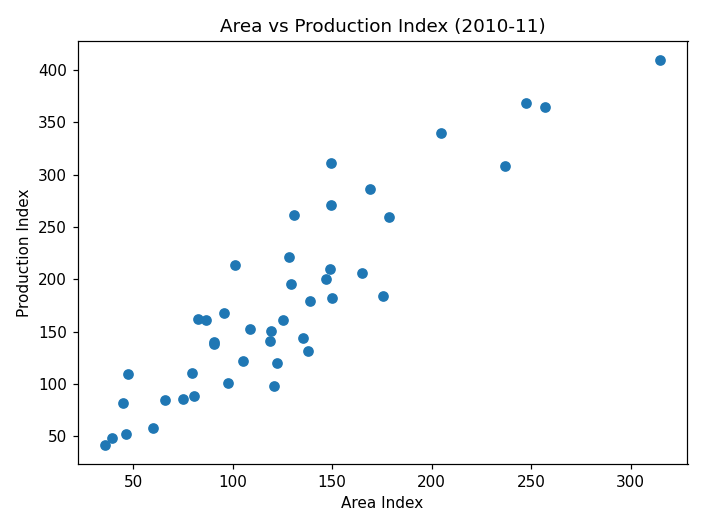

np.float64(0.9047095622136678)

In [20]:
plt.scatter(df_crops['Area 2010-11'], df_crops['Production 2010-11'])
plt.title('Area vs Production Index (2010-11)')
plt.xlabel('Area Index')
plt.ylabel('Production Index')
plt.show()
df_crops['Area 2010-11'].corr(df_crops['Production 2010-11'])

## 5. Summary numbers

In [21]:
df_crops['Category'].value_counts()

Category
Oilseeds               9
Cereals                8
Spices                 8
Fibres                 5
Fruits & Vegetables    5
Plantation             4
Pulses                 3
Other Cash Crops       2
Name: count, dtype: int64

In [22]:
df_crops[['Production 2010-11', 'Area 2010-11', 'Yield 2010-11']].describe().round(1)

       Production 2010-11  Area 2010-11  Yield 2010-11
count                44.0          44.0           44.0
mean                177.8         125.8          142.0
std                  91.8          60.2           35.1
min                  42.1          36.1           80.8
25%                 110.2          85.8          116.5
50%                 161.0         121.6          133.2
75%                 215.6         149.5          166.7
max                 409.1         314.7          230.9

In [23]:
df_crops.set_index('Crop')['Yield 2010-11'].sort_values(ascending=False).head(5)

Crop
Sannhamp        230.9
Jute            211.5
Cotton(lint)    207.9
Coriander       199.9
Cardamom        196.1
Name: Yield 2010-11, dtype: float64

In [24]:
growth.tail(5).round(1)

Crop
Black pepper   -24.7
Coconut        -31.5
Mesta          -36.1
Safflower      -37.4
Sunflower      -46.9
Name: Growth %, dtype: float64

In [25]:
df[df['Type'] == 'Group Total'][['Crop', 'Production 2006-07', 'Production 2010-11']]

                         Crop  Production 2006-07  Production 2010-11
0            Total Foodgrains               158.8               178.9
9              Coarse Cereals               138.5               178.4
10                    Cereals               164.1               183.1
14               Total Pulses               130.3               167.4
15      Total Non-Food grains               155.4               168.4
16             Total Oilseeds               148.2               169.0
26              Nine Oilseeds               147.1               196.7
29               Total Fibers               186.1               239.3
33               Jute & Mesta               200.7               189.1
38               Total Spices              1427.7              1790.6
47  Total Fruits & Vegetables               162.6               274.5